In [72]:
import pyvista as pv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import SymLogNorm

%matplotlib widget

In [73]:
## Reading data from saved files
Ve = 0.5
sparse_factor = 3
save_dir = 'E:/Research/Work/202405_solar_storm/reconstruction/sparse_factor=' + str(sparse_factor) + '/'
data_type = 1 # 0 for original field; 1 for resulted field
if data_type == 0:
    save_name = 'origin_field_data_' + str(Ve) + '.csv'
elif data_type == 1: 
    save_name = 'result_field_data_' + str(Ve) + '.csv'
data = pd.read_csv(save_dir+save_name)

In [74]:
## Extracting dataframes
xx = data['xx'].values
yy = data['yy'].values
zz = data['zz'].values

if data_type == 0:
    Bx = data['data_cube_Bx'].values
    By = data['data_cube_By'].values
    Bz = data['data_cube_Bz'].values
    if sparse_factor == 3:
        nx, ny, nz = 401, 171, 149
    elif sparse_factor == 5:
        nx, ny, nz = 241, 103, 90
    elif sparse_factor == 10: 
        nx, ny, nz = 121, 52, 46
    elif sparse_factor == 25:
        nx, ny, nz = 49, 21, 19
elif data_type == 1:
    Bx = data['Bx'].values
    By = data['By'].values
    Bz = data['Bz'].values  
    if sparse_factor == 3:
        nx, ny, nz = 257, 171, 149
    elif sparse_factor == 5:
        nx, ny, nz = 129, 103, 89
    elif sparse_factor == 10: 
        nx, ny, nz = 65, 52, 46
    elif sparse_factor == 25:
        nx, ny, nz = 33, 21, 19

# ReshaIIng saved data based on considering time range
xx = xx.reshape((nx, ny, nz))
yy = yy.reshape((nx, ny, nz))
zz = zz.reshape((nx, ny, nz)) # [km]
Bx = Bx.reshape((nx, ny, nz))
By = By.reshape((nx, ny, nz))
Bz = Bz.reshape((nx, ny, nz)) # [G]

# Bx = np.nan_to_num(Bx, nan=0.0)
# By = np.nan_to_num(By, nan=0.0)
# Bz = np.nan_to_num(Bz, nan=0.0)

In order to simplify the calculation, we perfer to use the International System of Units (SI).

In [75]:
## SI units
xx_SI = xx * 1e3 # [m]
yy_SI = yy * 1e3 # [m]
zz_SI = zz * 1e3 # [m]
Bx_SI = Bx * 1e-4 # [T]
By_SI = By * 1e-4 # [T]
Bz_SI = Bz * 1e-4 # [T]

xx_Mm = xx_SI * 1e-6 # [Mm]
yy_Mm = yy_SI * 1e-6 # [Mm]
zz_Mm = zz_SI * 1e-6 # [Mm]

In [76]:
## Import model-S structure data
model_S_limited = 'solar_models/structure/model_S/cptrho.l5bi.d.15c'
# from: https://users-phys.au.dk/~jcd/solar_models/cptrho.l5bi.d.15c

def read_model_S_limited_format(file=model_S_limited):
    """
    The limited formatted data for model S includes a smaller set of data in a whitespace delimited text file.

    This routine extracts the grid data, and then returns a dictionary object containing pandas dataframes.  The global data does not exist and is set to None.
    """
    col_names = ['r', 'c', 'rho', 'p', 'Gamma_1', 'T']
    data = pd.read_csv(file, delim_whitespace=True, comment='#', names=col_names)
    structure = {'global':None, 'data':data}
    return structure

structure = read_model_S_limited_format()

In [77]:
## Extracting model-S variables
r_model_Rs = np.array(structure['data']['r']) # [Rs]
cs_model = np.array(structure['data']['c']) # [cm/s]
rho_model = np.array(structure['data']['rho']) # [g/cm3]
p_model = np.array(structure['data']['p']) # [dyn/cm2]
Gamma_model = np.array(structure['data']['Gamma_1'])
T_model = np.array(structure['data']['T']) # [K]
nr = len(r_model_Rs)

Again, use the SI units.

In [78]:
## SI units
cs_model_SI = cs_model * 1e-2 # [m/s]
rho_model_SI = rho_model * 1e3 # [kg/m3]
p_model_SI = p_model * 1e-1 # [N/m2]

Rs = 6.955e8 # [m]
z_model_inner_SI = r_model_Rs * Rs # [m]
z_model_outer_SI = z_model_inner_SI - Rs # [m]
z_model_inner_Mm = z_model_inner_SI * 1e-6 # [Mm]
z_model_outer_Mm = z_model_outer_SI * 1e-6 # [Mm]

zz_arr_SI = zz_SI[1, 1, :] # [m]
zz_arr_Mm = zz_arr_SI * 1e-6 # [Mm]

Check the variables provided by model S first, and mark different regions of solar structure. 

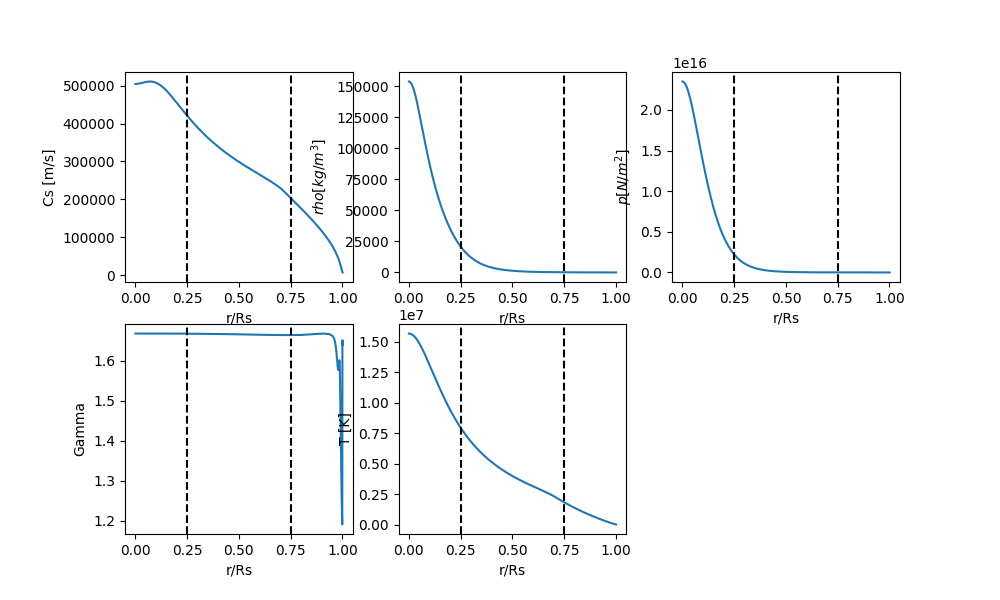

In [79]:
## Checking provided variables
fig = plt.figure(figsize=(10,6))

plt.subplot(2,3,1)
plt.plot(r_model_Rs, cs_model_SI)
plt.axvline(x=0.25, color='k', linestyle='--')
plt.axvline(x=0.75, color='k', linestyle='--')
plt.xlabel('r/Rs')
plt.ylabel('Cs [m/s]')

plt.subplot(2,3,2)
plt.plot(r_model_Rs, rho_model_SI)
plt.axvline(x=0.25, color='k', linestyle='--')
plt.axvline(x=0.75, color='k', linestyle='--')
plt.xlabel('r/Rs')
plt.ylabel('$rho [kg/m^3]$')

plt.subplot(2,3,3)
plt.plot(r_model_Rs, p_model_SI)
plt.axvline(x=0.25, color='k', linestyle='--')
plt.axvline(x=0.75, color='k', linestyle='--')
plt.xlabel('r/Rs')
plt.ylabel('$p [N/m^2]$')

plt.subplot(2,3,4)
plt.plot(r_model_Rs, Gamma_model)
plt.axvline(x=0.25, color='k', linestyle='--')
plt.axvline(x=0.75, color='k', linestyle='--')
plt.xlabel('r/Rs')
plt.ylabel('Gamma')

plt.subplot(2,3,5)
plt.plot(r_model_Rs, T_model)
plt.axvline(x=0.25, color='k', linestyle='--')
plt.axvline(x=0.75, color='k', linestyle='--')
plt.xlabel('r/Rs')
plt.ylabel('T [K]')

plt.show()

Interpolate the data from the Standard Solar Model to the coordinate of photosphere surface. 

In [80]:
## Interpolating from model-S to reconstructed grid
from scipy.interpolate import interp1d

def interp_model2recon(z_model, var_model, z_interp, kind='linear'):
    
    f = interp1d(z_model, var_model, kind=kind)
    var_interp = f(z_interp)
    
    return var_interp

cs_interp_SI = interp_model2recon(z_model_outer_SI, cs_model_SI, zz_arr_SI)
rho_interp_SI = interp_model2recon(z_model_outer_SI, rho_model_SI, zz_arr_SI)
p_interp_SI = interp_model2recon(z_model_outer_SI, p_model_SI, zz_arr_SI)
Gamma_interp = interp_model2recon(z_model_outer_SI, Gamma_model, zz_arr_SI)

rho_mat_SI = np.tile(rho_interp_SI, (nx, ny, 1)) # [kg/m3]
p_mat_SI = np.tile(p_interp_SI, (nx, ny, 1)) # [N/m2]
Gamma_mat = np.tile(Gamma_interp, (nx, ny, 1))

And check the variables in the range of interest.

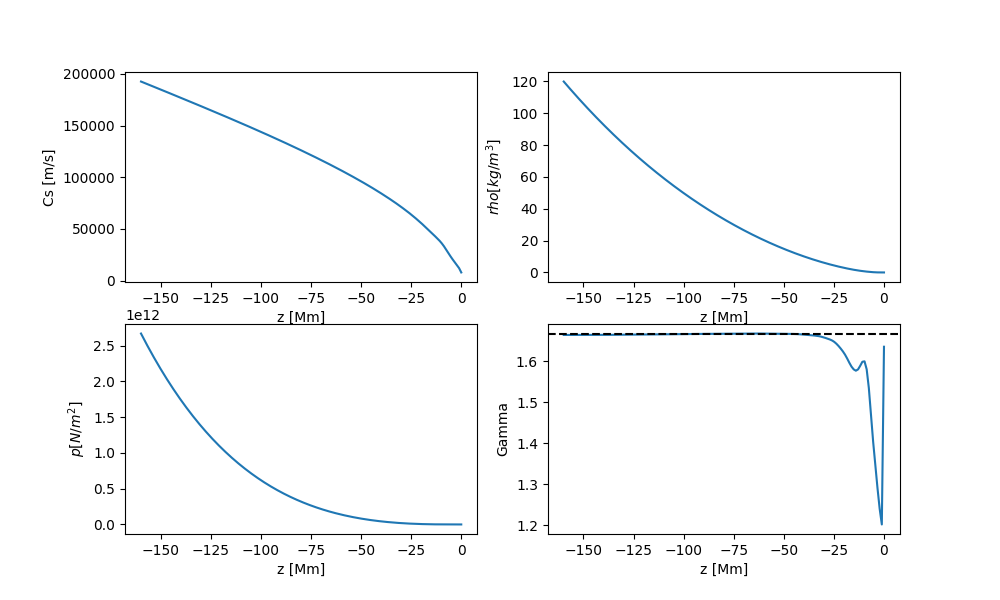

In [81]:
## Checking interpolated variables
fig = plt.figure(figsize=(10,6))

plt.subplot(2,2,1)
plt.plot(zz_arr_Mm, cs_interp_SI)
plt.xlabel('z [Mm]')
plt.ylabel('Cs [m/s]')

plt.subplot(2,2,2)
plt.plot(zz_arr_Mm, rho_interp_SI)
plt.xlabel('z [Mm]')
plt.ylabel('$rho [kg/m^3]$')

plt.subplot(2,2,3)
plt.plot(zz_arr_Mm, p_interp_SI)
plt.xlabel('z [Mm]')
plt.ylabel('$p [N/m^2]$')

plt.subplot(2,2,4)
plt.plot(zz_arr_Mm, Gamma_interp)
plt.axhline(y=5/3, color='k', linestyle='--')
plt.xlabel('z [Mm]')
plt.ylabel('Gamma')

plt.show()

Two intermediate variables are helpful to check magnetic buoyancy instabilities. 

(1) Firstly, the gravity coefficient, $g$, is calculated as: 

$$g(r) = \frac{GM(r)}{r^2} = \frac{G\int_{0}^{r}{\rho(r) \cdot 4 \pi r^2 {\rm d}r}}{r^2} \tag{1}$$

In [82]:
## Calculating gravity coefficient
z_model_inner_SI[-1] = 1

M_model = np.zeros_like(r_model_Rs)
M_model[-1] = 0
for ir in range(1, nr):
    dM = rho_model_SI[nr-ir] * 4 * np.pi * z_model_inner_SI[nr-ir]**2 \
        * (z_model_inner_SI[nr-ir-1] - z_model_inner_SI[nr-ir]) # [kg]
    M_model[nr-ir-1] = M_model[nr-ir] + dM

# gravity coefficient
G_coef = 6.67408e-11 # [m3/kg/s2]
g_model = G_coef * M_model / z_model_inner_SI ** 2 # [m/s2]

# interpolation
M_interp = interp_model2recon(z_model_outer_SI, M_model, zz_arr_SI)
g_interp = interp_model2recon(z_model_outer_SI, g_model, zz_arr_SI)

g_mat = np.tile(g_interp, (nx, ny, 1))

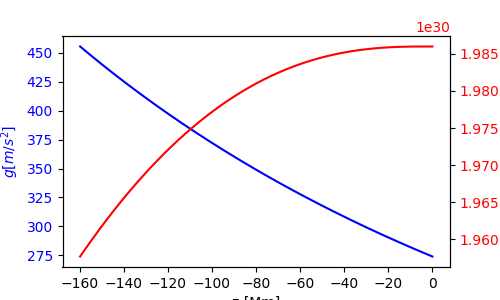

In [83]:
## Plotting gravity acceleration
fig, ax1 = plt.subplots(figsize=(5,3))

color1 = 'blue'
ax1.plot(zz_arr_Mm, g_interp, color=color1)
ax1.set_xlabel('z [Mm]')
ax1.set_ylabel('$g [m/s^2]$', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = 'red'
ax2.plot(zz_arr_Mm, M_interp, color=color2)
ax2.set_ylabel('M [kg]', color=color2)
ax2.tick_params(axis='y', labelcolor=color2)

plt.show()

(2) Second, the $Brunt-V\ddot{a}is\ddot{a}l\ddot{a}$ frequency, $N$, is calculated as: 

$$ N^2(r) = \frac{g(r)}{\gamma(r)} \frac{\rm d}{{\rm d}z} [\ln{p(r) \rho(r)^{-\gamma(r)}}] \tag{2}$$

There are two ways to calculate it, but always remember to **calculate it in the finer grid of model first**, and then interpolate it to the grid of reconstruction, as the calculation of $N^2$ depends on the first-difference of $z$, . 

> a) Calcualte the frequency directly from Equ.(2). One can find that if $\gamma$ is a function of the radius $r$, B-V frequency obtained from Equ.(2) depends on the selected unit system. Here we use the SI system, and first check the radial profile of the intermedian variable, $p \rho^{-\gamma}$.

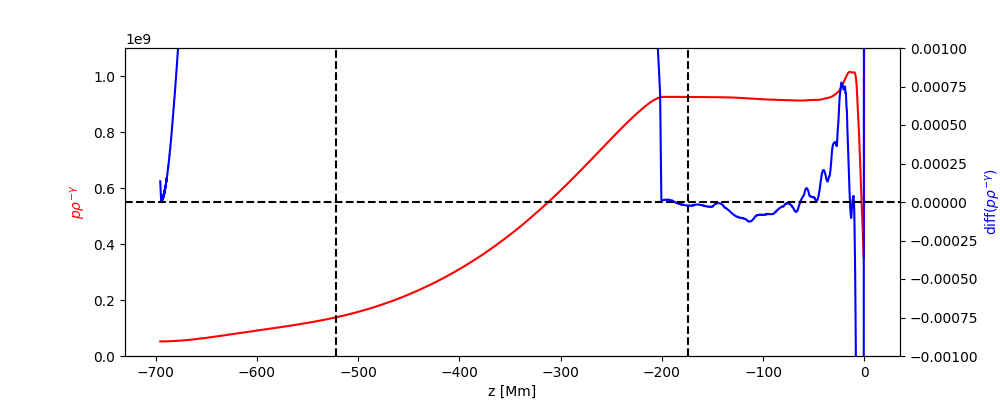

In [84]:
## Checking the intermedian variable
prg_model = p_model_SI * rho_model_SI ** (-Gamma_model)

fig, ax1 = plt.subplots(figsize=(10,4))

ax1.plot(z_model_outer_Mm, prg_model, 'r')
plt.axvline(x=-0.25*Rs/1e6, color='k', linestyle='--')
plt.axvline(x=-0.75*Rs/1e6, color='k', linestyle='--')
plt.xlabel('z [Mm]')
ax1.set_ylabel(r'$p \rho^{-\gamma}$', color='r')
ax1.set_ylim([0, 1.1e9])

ax2 = ax1.twinx()
ax2.plot(z_model_outer_Mm[1:], -np.diff(np.log(prg_model)), 'b')
plt.axhline(y=0, color='k', linestyle='--')
ax2.set_ylabel(r'diff($p \rho^{-\gamma}$)', color='b')
ax2.set_ylim([-1e-3, 1e-3])

plt.show()

In [85]:
## Calculating B-V frequency based on the original form
def calc_N2_origi(g_arr, gamma_arr, r_arr, prg_arr):
    N2_arr = g_arr[:-1] / gamma_arr[:-1] * np.diff(np.log(prg_arr)) / np.diff(r_arr)
    return N2_arr

N2_model_origi = calc_N2_origi(g_model, Gamma_model, z_model_inner_SI, prg_model)

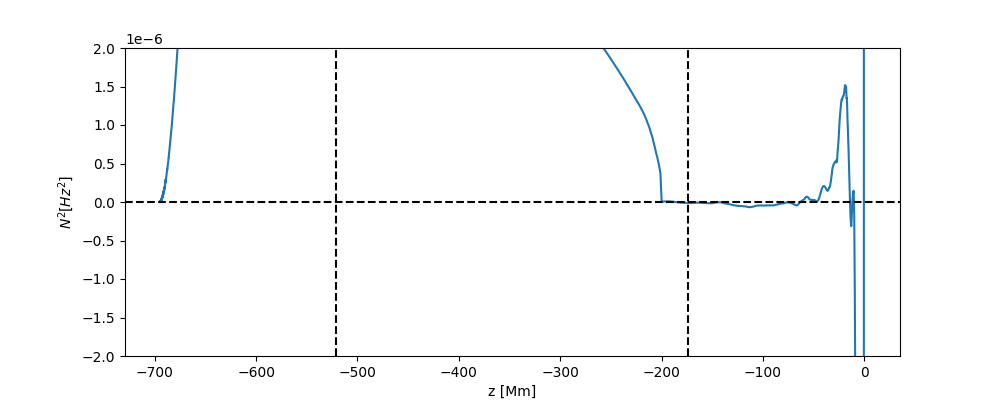

In [86]:
## Plotting B-V frequency
plt.figure(figsize=(10,4))

plt.plot(z_model_outer_Mm[:-1], N2_model_origi)
plt.axhline(y=0, color='k', linestyle='--')
plt.axvline(x=-0.25*Rs/1e6, color='k', linestyle='--')
plt.axvline(x=-0.75*Rs/1e6, color='k', linestyle='--')
plt.xlabel('z [Mm]')
plt.ylabel('$N^2 [Hz^2]$')
plt.ylim([-2e-6, 2e-6])

plt.show()

> b) To avoid the potential inconsistence caused by unit system, we can also use the expansion form of Equ.(2), that is: 

$$ N^2(r) = \frac{g(r)}{\gamma(r)} \left[ \frac{1}{p(r)} \frac{dp(r)}{dz} - \frac{\gamma(r)}{\rho(r)} \frac{d\rho(r)}{dz} - \ln{\rho(r)} \frac{d\gamma(r)}{dz} \right] \tag{2'}$$

In [87]:
## Calculating B-V frequency based on the expansion form
def calc_N2_expan(g_arr, p_arr, Gamma_arr, rho_arr, r_arr):
    nr = len(g_arr)
    N2_arr = np.zeros_like(g_arr)
    for ir in range(1, nr):
        N2_arr[ir] = (g_arr[ir-1] + g_arr[ir]) / (Gamma_arr[ir-1] + Gamma_arr[ir]) * \
            (2 / (p_arr[ir-1] + p_arr[ir]) * (p_arr[ir-1] - p_arr[ir]) - \
                (Gamma_arr[ir-1] + Gamma_arr[ir]) / (rho_arr[ir-1] + rho_arr[ir]) * (rho_arr[ir-1] - rho_arr[ir]) - \
                    np.log((rho_arr[ir-1] + rho_arr[ir]) / 2) * (Gamma_arr[ir-1] - Gamma_arr[ir])) \
                        / (r_arr[ir-1] - r_arr[ir])
    return N2_arr

N2_model_expan = calc_N2_expan(g_model, p_model_SI, Gamma_model, rho_model_SI, z_model_inner_SI)

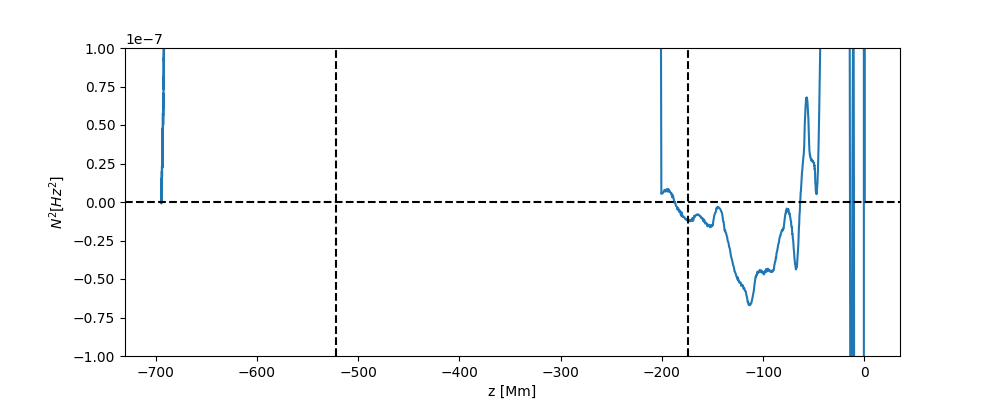

In [88]:
## Plotting B-V frequency
plt.figure(figsize=(10,4))

plt.plot(z_model_outer_Mm, N2_model_expan)
plt.axhline(y=0, color='k', linestyle='--')
plt.axvline(x=-0.25*Rs/1e6, color='k', linestyle='--')
plt.axvline(x=-0.75*Rs/1e6, color='k', linestyle='--')
plt.xlabel('z [Mm]')
plt.ylabel('$N^2 [Hz^2]$')
plt.ylim([-1e-7, 1e-7])

plt.show()

Now, select the results of $N^2$ between the two methods, and interpolate it to the reconstruction grid. 

In [89]:
# interpolation
N2_model = N2_model_expan # 'N2_model_origi' or 'N2_model_expan'
N2_interp = interp_model2recon(z_model_outer_SI, N2_model, zz_arr_SI)

N2_mat = np.tile(N2_interp, (nx, ny, 1))

It is worth noticing that the Standard Solar Model only provides a spherically symmetric distribution of these pyhsical variables, including $p$, $\rho$ and $C_s$. However, the trigger of magnetic buoyancy requires the imbalance of gas pressure. In fact, the gas pressure will be weaker where the magnetic field is stronger, leading to the rising of plasma.

(1) According to the balance of total pressure:

$$p + \frac{B^2}{2\mu_0} = constant \tag{3}$$

Setting a base level of $p_{base}$, the gas pressure is updated from $p$ to $p_{ud}$:

$$p_{ud} = p_{base} + p - \frac{B^2}{2\mu_0} \tag{4}$$

Remember to check there is no negative pressure.

In [90]:
## Updating gas pressure
mu0 = 1.2566e-6 # [kg m/s2/A2]
B_mod2 = Bx_SI ** 2 + By_SI ** 2 + Bz_SI ** 2
B_mod = np.sqrt(B_mod2)

p_base_arr = np.nanmean(B_mod2/2/mu0, axis=(0,1))
p_base = np.tile(p_base_arr, (nx, ny, 1))
p_mat_ud = p_base + p_mat_SI - B_mod2/2/mu0 # [kg/m2]

if np.min(p_mat_ud) <= 0:
    print('ValueError: Negative Pressure!')

C:\Users\rzhuo\AppData\Local\Temp\ipykernel_79704\3224113026.py:6: RuntimeWarning: Mean of empty slice
  p_base_arr = np.nanmean(B_mod2/2/mu0, axis=(0,1))


(2) According to the Equation of State (EoS): 

$$p \rho^{-\gamma} = constant \tag{5}$$

Assuming $\gamma$ to be an invariant at the sphere surface, we further update the density from $\rho$ to $\rho_{ud}$: 

$$\rho_{ud} = \rho \left( \frac{p_{ud}}{p} \right)^{1/\gamma} \tag{6}$$

In [91]:
## Updating mass density
rho_mat_ud = rho_mat_SI * (p_mat_ud / p_mat_SI) ** (1 / Gamma_mat)

C:\Users\rzhuo\AppData\Local\Temp\ipykernel_79704\954018677.py:2: RuntimeWarning: invalid value encountered in power
  rho_mat_ud = rho_mat_SI * (p_mat_ud / p_mat_SI) ** (1 / Gamma_mat)


Through the above approach, we can obtain the self-consistent system with pressure balance. 

Then we update the sound speed $C_s$:

$$C_s^2 = \gamma p /\rho \tag{7}$$

and calculate the Alfven speed, $V_A$: 

$$V_A^2 = \frac{B^2}{\mu_0 \rho}\tag{8}$$

while Brunt-Vaeisaelae frequency $N^2$ only depends on the term, $\ln{p(r) \rho(r)^{-\gamma(r)}}$, so there is no updation for it.

In [92]:
## Calculating sound speed
Cs2_mat = Gamma_mat * p_mat_ud / rho_mat_ud # [m/s]

## Calculating Alfven speed
Va2_mat = B_mod2 / mu0 / rho_mat_ud # [m/s]

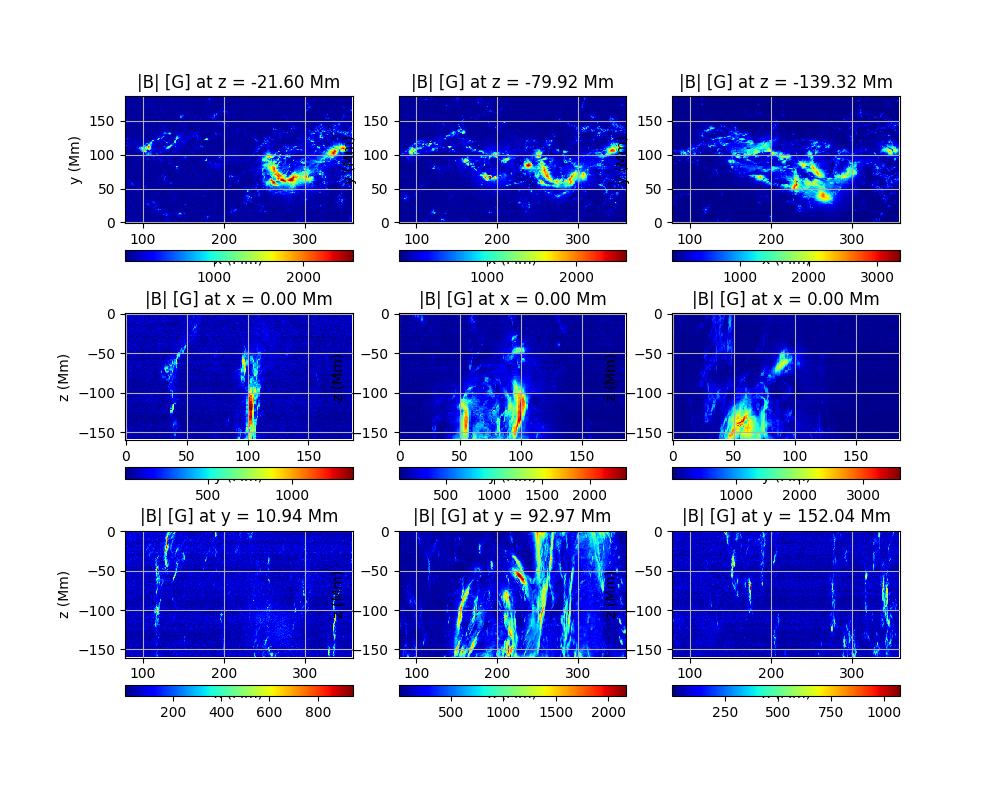

In [93]:
## Plotting the profile of magnetic field strength
fig, axs = plt.subplots(3, 3, figsize=(10, 8))

z_indices = [20, nz//2, nz-20]

for i, z_idx in enumerate(z_indices):
    B_mod_slice = B_mod[:,:,z_idx] * 1e4
    c = axs[0,i].pcolormesh(xx_Mm[:,:,z_idx], yy_Mm[:,:,z_idx], B_mod_slice, cmap='jet')
    axs[0,i].set_title(f'|B| [G] at z = {zz_Mm[0,0,z_idx]:.2f} Mm')
    axs[0,i].set_xlabel('x (Mm)')
    axs[0,i].set_ylabel('y (Mm)')
    axs[0,i].grid()
    plt.colorbar(c, ax=axs[0,i], orientation='horizontal')

x_indices = [10, nx//2, nz-10]

for i, x_idx in enumerate(x_indices):
    B_mod_slice = B_mod[x_idx,:,:] * 1e4
    c = axs[1,i].pcolormesh(yy_Mm[x_idx,:,:], zz_Mm[x_idx,:,:], B_mod_slice, cmap='jet')
    axs[1,i].set_title(f'|B| [G] at x = {zz_Mm[x_idx,0,0]:.2f} Mm')
    axs[1,i].set_xlabel('y (Mm)')
    axs[1,i].set_ylabel('z (Mm)')
    axs[1,i].grid()
    plt.colorbar(c, ax=axs[1,i], orientation='horizontal')

y_indices = [10, ny//2, nz-10]

for i, y_idx in enumerate(y_indices):
    B_mod_slice = B_mod[:,y_idx,:] * 1e4
    c = axs[2,i].pcolormesh(xx_Mm[:,y_idx,:], zz_Mm[:,y_idx,:], B_mod_slice, cmap='jet')
    axs[2,i].set_title(f'|B| [G] at y = {yy_Mm[0,y_idx,0]:.2f} Mm')
    axs[2,i].set_xlabel('x (Mm)')
    axs[2,i].set_ylabel('z (Mm)')
    axs[2,i].grid()
    plt.colorbar(c, ax=axs[2,i], orientation='horizontal')

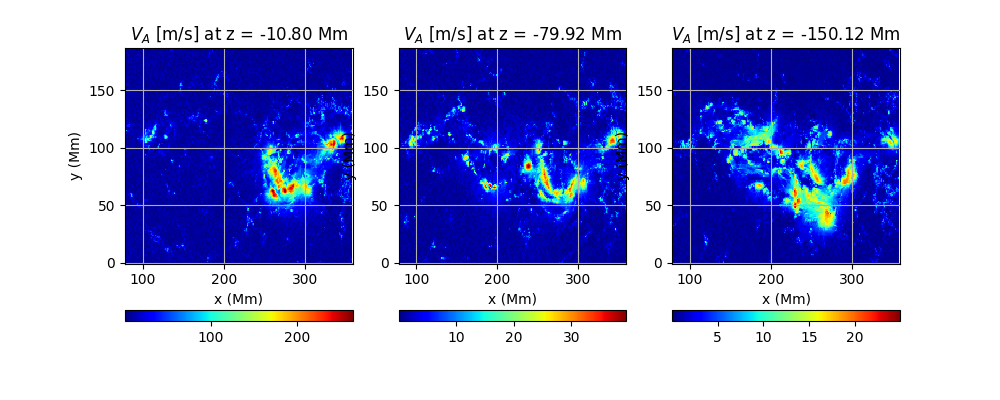

In [94]:
## Plotting the profile of Alfven speed
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

z_indices = [10, nz//2, nz-10]

for i, z_idx in enumerate(z_indices):
    Va_slice = np.sqrt(Va2_mat[:,:,z_idx])
    c = axs[i].pcolormesh(xx_Mm[:,:,z_idx], yy_Mm[:,:,z_idx], Va_slice, cmap='jet')
    axs[i].set_title(f'$V_A$ [m/s] at z = {zz_Mm[0,0,z_idx]:.2f} Mm')
    axs[i].set_xlabel('x (Mm)')
    axs[i].set_ylabel('y (Mm)')
    axs[i].grid()
    plt.colorbar(c, ax=axs[i], orientation='horizontal')

Here, we consider two types of magnetic buoyancy instabilities, the Interchange mode and the undular mode. 

(1) Interchange mode (Interchange Instability, II). 

This instability happens in an environment where $\vec{k} \perp \vec{B}$, and the field lines do not bend. It's something like Rayleigh-Taylor Instability, and it is triggered when: 

$$\frac{d}{dz}\ln{\left ({B/\rho }\right )}<-\frac{{{C}_{s}^{2}}}{g}\frac{{{N}^{2}}}{{{V}_{A}^{2}}} \tag{4}$$

In [95]:
## Checking interchange mode
II_lhs = np.zeros((nx, ny, nz))
II_rhs = np.zeros((nx, ny, nz))

ln_Brho = np.log(B_mod / rho_mat_ud)

for iz in range(1, nz):
    II_lhs[:,:,iz] = (ln_Brho[:,:,iz-1] - ln_Brho[:,:,iz]) / (zz_arr_SI[iz-1] - zz_arr_SI[iz]) # [m-1]

II_rhs = - Cs2_mat * N2_mat / g_mat / Va2_mat

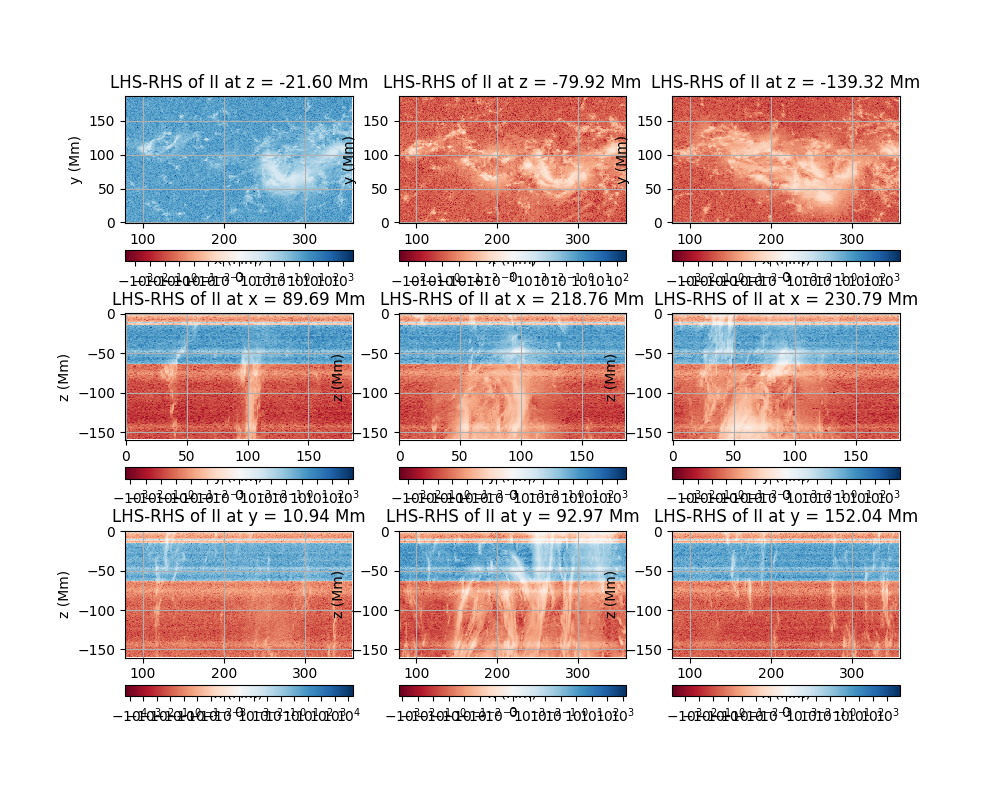

In [ ]:
## Plotting criterion for Interchange Instability
cri_II = II_lhs - II_rhs

fig, axs = plt.subplots(3, 3, figsize=(10, 8))

z_indices = [20, nz//2, nz-20]

for i, z_idx in enumerate(z_indices):
    cri_II_slice = cri_II[:,:,z_idx]
    max_abs_cri_II = np.nanmax(np.abs(cri_II_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_cri_II, vmax=max_abs_cri_II)
    c = axs[0,i].pcolormesh(xx_Mm[:,:,z_idx], yy_Mm[:,:,z_idx], cri_II_slice, cmap='bwr', norm=norm)
    axs[0,i].set_title(f'LHS-RHS of II at z = {zz_Mm[0,0,z_idx]:.2f} Mm')
    axs[0,i].set_xlabel('x (Mm)')
    axs[0,i].set_ylabel('y (Mm)')
    axs[0,i].grid()
    plt.colorbar(c, ax=axs[0,i], orientation='horizontal')

x_indices = [10, nx//2, nz-10]

for i, x_idx in enumerate(x_indices):
    cri_II_slice = cri_II[x_idx,:,:]
    max_abs_cri_II = np.nanmax(np.abs(cri_II_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_cri_II, vmax=max_abs_cri_II)
    c = axs[1,i].pcolormesh(yy_Mm[x_idx,:,:], zz_Mm[x_idx,:,:], cri_II_slice, cmap='bwr', norm=norm)
    axs[1,i].set_title(f'LHS-RHS of II at x = {xx_Mm[x_idx,0,0]:.2f} Mm')
    axs[1,i].set_xlabel('y (Mm)')
    axs[1,i].set_ylabel('z (Mm)')
    axs[1,i].grid()
    plt.colorbar(c, ax=axs[1,i], orientation='horizontal')

y_indices = [10, ny//2, nz-10]

for i, y_idx in enumerate(y_indices):
    cri_II_slice = cri_II[:,y_idx,:]
    max_abs_cri_II = np.nanmax(np.abs(cri_II_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_cri_II, vmax=max_abs_cri_II)
    c = axs[2,i].pcolormesh(xx_Mm[:,y_idx,:], zz_Mm[:,y_idx,:], cri_II_slice, cmap='bwr', norm=norm)
    axs[2,i].set_title(f'LHS-RHS of II at y = {yy_Mm[0,y_idx,0]:.2f} Mm')
    axs[2,i].set_xlabel('x (Mm)')
    axs[2,i].set_ylabel('z (Mm)')
    axs[2,i].grid()
    plt.colorbar(c, ax=axs[2,i], orientation='horizontal')

(2) Undular mode (Parker Instability, PI)

This instability happens in an environment where $\vec{k} \parallel \vec{B}$, and the field lines bend so that particles can slide from peaks to troughs. The criterion for this instability is given by Acheson (1979): 

$$\frac{d}{dz}\ln{B}<-\frac{{{C}_{s}^{2}}}{g}\left [{{{k}_{\parallel }^{2}}\left ({1+\frac{{{k}_{z}^{2}}}{{{k}_{\perp }^{2}}}}\right )+\frac{{{N}^{2}}}{{{V}_{A}^{2}}}}\right ] \tag{5}$$

where it is assumed that $k_{\parallel} \ll k_{\perp}, k_z$ (Acheson, 1979).  

In [97]:
## Checking undular mode
PI_lhs = np.zeros((nx, ny, nz))
PI_rhs = np.zeros((nx, ny, nz))

# assuming wave-number
lambda_para = (np.max(xx_SI) - np.min(xx_SI)) / 2 # [m]
lambda_perp = (np.max(yy_SI) - np.min(yy_SI)) / 20 # [m]
lambda_z = (np.max(zz_SI) - np.min(zz_SI)) / 20 # [m]

k_para = 1 / lambda_para # [m-1]
k_perp = 1 / lambda_perp # [m-1]
k_z = 1 / lambda_z # [m-1]

print('k_para [m-1]: ', k_para)
print('k_perp [m-1]: ', k_perp)
print('k_z [m-1]: ', k_z)

ln_B = np.log(B_mod)

for iz in range(1, nz):
    PI_lhs[:,:,iz] = (ln_B[:,:,iz-1] - ln_B[:,:,iz]) / ((zz_arr_SI[iz-1] - zz_arr_SI[iz])) # [m-1]

PI_rhs = - Cs2_mat / g_mat * (k_para ** 2 * (1 + k_z ** 2 / k_perp ** 2) + N2_mat / Va2_mat)

k_para [m-1]:  7.142476335729284e-09
k_perp [m-1]:  1.0755729070274687e-07
k_z [m-1]:  1.2512512512512512e-07


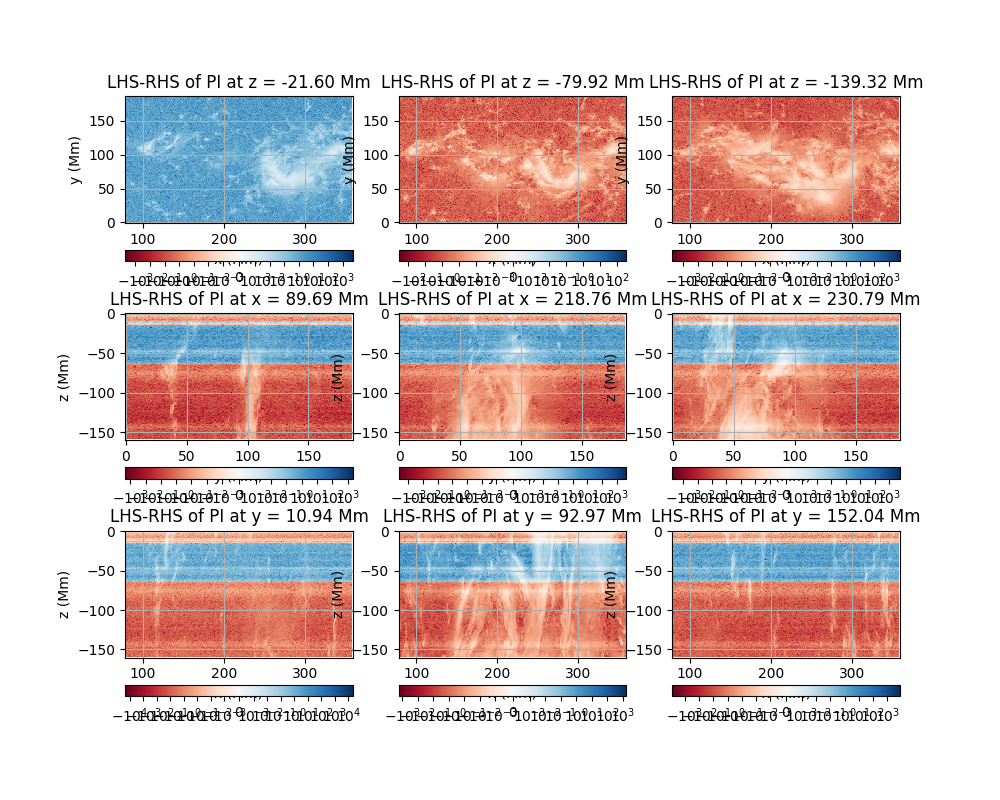

In [ ]:
## Plotting criterion for Parker Instability
cri_PI = PI_lhs - PI_rhs

fig, axs = plt.subplots(3, 3, figsize=(10, 8))

z_indices = [20, nz//2, nz-20]

for i, z_idx in enumerate(z_indices):
    cri_PI_slice = cri_PI[:,:,z_idx]
    max_abs_cri_PI = np.nanmax(np.abs(cri_PI_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_cri_PI, vmax=max_abs_cri_PI)
    c = axs[0,i].pcolormesh(xx_Mm[:,:,z_idx], yy_Mm[:,:,z_idx], cri_PI_slice, cmap='bwr', norm=norm)
    axs[0,i].set_title(f'LHS-RHS of PI at z = {zz_Mm[0,0,z_idx]:.2f} Mm')
    axs[0,i].set_xlabel('x (Mm)')
    axs[0,i].set_ylabel('y (Mm)')
    axs[0,i].grid()
    plt.colorbar(c, ax=axs[0,i], orientation='horizontal')

x_indices = [10, nx//2, nz-10]

for i, x_idx in enumerate(x_indices):
    cri_PI_slice = cri_PI[x_idx,:,:]
    max_abs_cri_PI = np.nanmax(np.abs(cri_PI_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_cri_PI, vmax=max_abs_cri_PI)
    c = axs[1,i].pcolormesh(yy_Mm[x_idx,:,:], zz_Mm[x_idx,:,:], cri_PI_slice, cmap='bwr', norm=norm)
    axs[1,i].set_title(f'LHS-RHS of PI at x = {xx_Mm[x_idx,0,0]:.2f} Mm')
    axs[1,i].set_xlabel('y (Mm)')
    axs[1,i].set_ylabel('z (Mm)')
    axs[1,i].grid()
    plt.colorbar(c, ax=axs[1,i], orientation='horizontal')

y_indices = [10, ny//2, nz-10]

for i, y_idx in enumerate(y_indices):
    cri_PI_slice = cri_PI[:,y_idx,:]
    max_abs_cri_PI = np.nanmax(np.abs(cri_PI_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_cri_PI, vmax=max_abs_cri_PI)
    c = axs[2,i].pcolormesh(xx_Mm[:,y_idx,:], zz_Mm[:,y_idx,:], cri_PI_slice, cmap='bwr', norm=norm)
    axs[2,i].set_title(f'LHS-RHS of PI at y = {yy_Mm[0,y_idx,0]:.2f} Mm')
    axs[2,i].set_xlabel('x (Mm)')
    axs[2,i].set_ylabel('z (Mm)')
    axs[2,i].grid()
    plt.colorbar(c, ax=axs[2,i], orientation='horizontal')

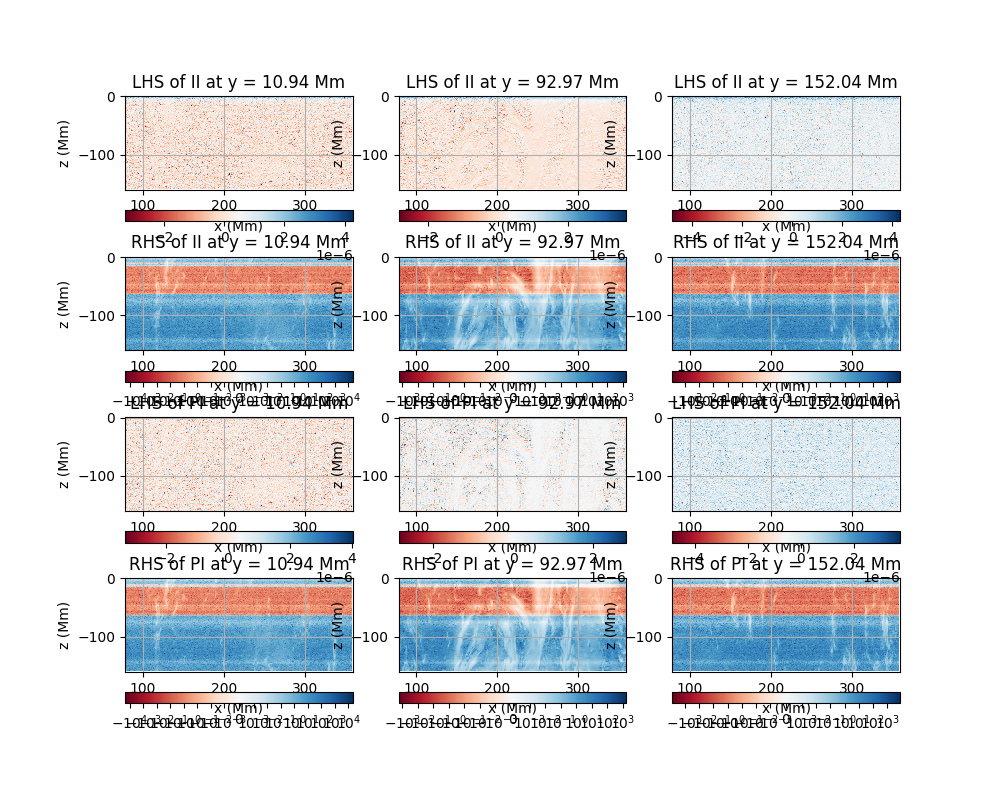

In [ ]:
## Plotting the LHS and RHS for both Instabilities
fig, axs = plt.subplots(4, 3, figsize=(10, 8))

y_indices = [10, ny//2, nz-10]

for i, y_idx in enumerate(y_indices):
    II_lhs_slice = II_lhs[:,y_idx,:]
    max_abs_II_lhs = np.nanmax(np.abs(II_lhs_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_II_lhs, vmax=max_abs_II_lhs)
    c = axs[0,i].pcolormesh(xx_Mm[:,y_idx,:], zz_Mm[:,y_idx,:], II_lhs_slice, cmap='bwr')
    axs[0,i].set_title(f'LHS of II at y = {yy_Mm[0,y_idx,0]:.2f} Mm')
    axs[0,i].set_xlabel('x (Mm)')
    axs[0,i].set_ylabel('z (Mm)')
    axs[0,i].grid()
    plt.colorbar(c, ax=axs[0,i], orientation='horizontal')

for i, y_idx in enumerate(y_indices):
    II_rhs_slice = II_rhs[:,y_idx,:]
    max_abs_II_rhs = np.nanmax(np.abs(II_rhs_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_II_rhs, vmax=max_abs_II_rhs)
    c = axs[1,i].pcolormesh(xx_Mm[:,y_idx,:], zz_Mm[:,y_idx,:], II_rhs_slice, cmap='bwr', norm=norm)
    axs[1,i].set_title(f'RHS of II at y = {yy_Mm[0,y_idx,0]:.2f} Mm')
    axs[1,i].set_xlabel('x (Mm)')
    axs[1,i].set_ylabel('z (Mm)')
    axs[1,i].grid()
    plt.colorbar(c, ax=axs[1,i], orientation='horizontal')

for i, y_idx in enumerate(y_indices):
    PI_lhs_slice = PI_lhs[:,y_idx,:]
    max_abs_PI_lhs = np.nanmax(np.abs(PI_lhs_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_PI_lhs, vmax=max_abs_PI_lhs)
    c = axs[2,i].pcolormesh(xx_Mm[:,y_idx,:], zz_Mm[:,y_idx,:], PI_lhs_slice, cmap='bwr')
    axs[2,i].set_title(f'LHS of PI at y = {yy_Mm[0,y_idx,0]:.2f} Mm')
    axs[2,i].set_xlabel('x (Mm)')
    axs[2,i].set_ylabel('z (Mm)')
    axs[2,i].grid()
    plt.colorbar(c, ax=axs[2,i], orientation='horizontal')

for i, y_idx in enumerate(y_indices):
    PI_rhs_slice = PI_rhs[:,y_idx,:]
    max_abs_PI_rhs = np.nanmax(np.abs(PI_rhs_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_PI_rhs, vmax=max_abs_PI_rhs)
    c = axs[3,i].pcolormesh(xx_Mm[:,y_idx,:], zz_Mm[:,y_idx,:], PI_rhs_slice, cmap='bwr', norm=norm)
    axs[3,i].set_title(f'RHS of PI at y = {yy_Mm[0,y_idx,0]:.2f} Mm')
    axs[3,i].set_xlabel('x (Mm)')
    axs[3,i].set_ylabel('z (Mm)')
    axs[3,i].grid()
    plt.colorbar(c, ax=axs[3,i], orientation='horizontal')

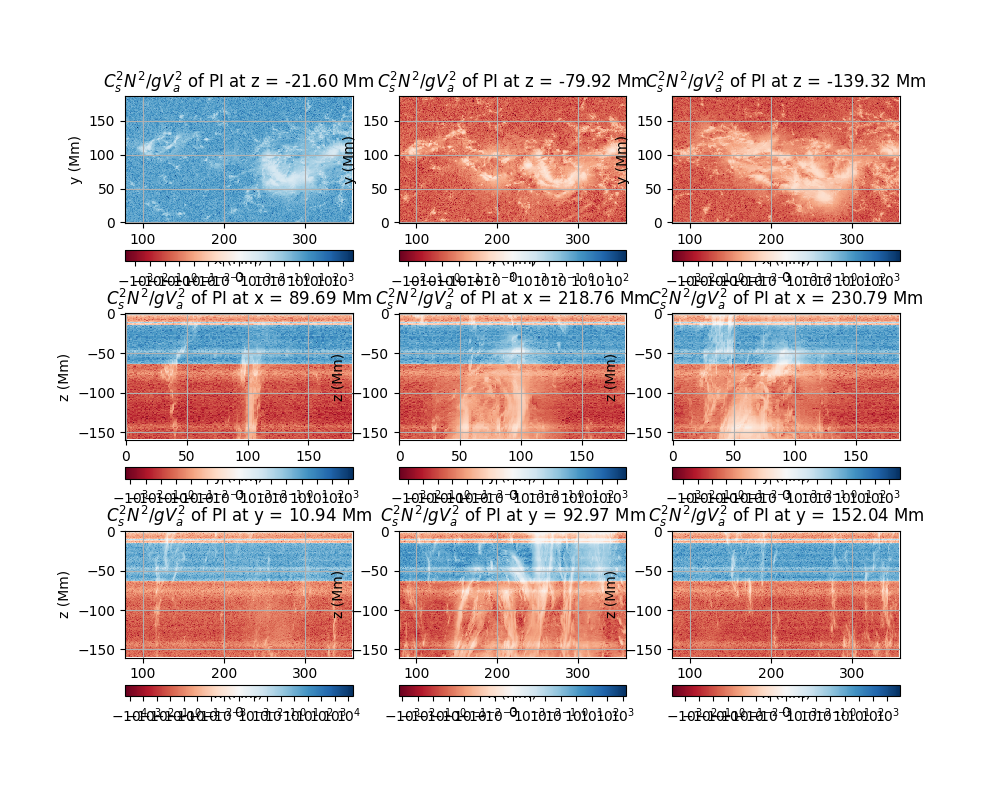

In [ ]:
## Plotting the term N2/Va2
N2Va2 = Cs2_mat / g_mat * N2_mat / Va2_mat

fig, axs = plt.subplots(3, 3, figsize=(10, 8))

z_indices = [20, nz//2, nz-20]

for i, z_idx in enumerate(z_indices):
    N2Va2_slice = N2Va2[:,:,z_idx]
    max_abs_N2Va2 = np.nanmax(np.abs(N2Va2_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_N2Va2, vmax=max_abs_N2Va2)
    c = axs[0,i].pcolormesh(xx_Mm[:,:,z_idx], yy_Mm[:,:,z_idx], N2Va2_slice, cmap='bwr', norm=norm)
    axs[0,i].set_title(f'$C_s^2 N^2/g V_a^2$ of PI at z = {zz_Mm[0,0,z_idx]:.2f} Mm')
    axs[0,i].set_xlabel('x (Mm)')
    axs[0,i].set_ylabel('y (Mm)')
    axs[0,i].grid()
    plt.colorbar(c, ax=axs[0,i], orientation='horizontal')

x_indices = [10, nx//2, nz-10]

for i, x_idx in enumerate(x_indices):
    N2Va2_slice = N2Va2[x_idx,:,:]
    max_abs_N2Va2 = np.nanmax(np.abs(N2Va2_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_N2Va2, vmax=max_abs_N2Va2)
    c = axs[1,i].pcolormesh(yy_Mm[x_idx,:,:], zz_Mm[x_idx,:,:], N2Va2_slice, cmap='bwr', norm=norm)
    axs[1,i].set_title(f'$C_s^2 N^2/g V_a^2$ of PI at x = {xx_Mm[x_idx,0,0]:.2f} Mm')
    axs[1,i].set_xlabel('y (Mm)')
    axs[1,i].set_ylabel('z (Mm)')
    axs[1,i].grid()
    plt.colorbar(c, ax=axs[1,i], orientation='horizontal')

y_indices = [10, ny//2, nz-10]

for i, y_idx in enumerate(y_indices):
    N2Va2_slice = N2Va2[:,y_idx,:]
    max_abs_N2Va2 = np.nanmax(np.abs(N2Va2_slice))
    norm = SymLogNorm(linthresh=1e-3, linscale=1, vmin=-max_abs_N2Va2, vmax=max_abs_N2Va2)
    c = axs[2,i].pcolormesh(xx_Mm[:,y_idx,:], zz_Mm[:,y_idx,:], N2Va2_slice, cmap='bwr', norm=norm)
    axs[2,i].set_title(f'$C_s^2 N^2/g V_a^2$ of PI at y = {yy_Mm[0,y_idx,0]:.2f} Mm')
    axs[2,i].set_xlabel('x (Mm)')
    axs[2,i].set_ylabel('z (Mm)')
    axs[2,i].grid()
    plt.colorbar(c, ax=axs[2,i], orientation='horizontal')